<a href="https://colab.research.google.com/github/gibranfp/CursoAprendizajeProfundo/blob/2027-1/notebooks/4c_vit_cifar10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Clasificación de imágenes con la arquitectura Vision Transformer (ViT)
En esta libreta programaremos, entrenaremos y evaluaremos un clasificador de imágenes basado en una arquitectura Vision Transformer (ViT).

In [1]:
from collections.abc import Callable
import copy
from math import sqrt

import matplotlib.pyplot as plt
import numpy as np

import torch as th
import torch.nn as nn
from torch.utils.tensorboard import SummaryWriter

import torchvision as tv
from torchvision.transforms import v2

from einops import rearrange

from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score, recall_score, precision_score
from sklearn.metrics import confusion_matrix

try:
  import torchmetrics
except ImportError:
  %pip install torchmetrics -qq
  import torchmetrics

from transformers import get_cosine_schedule_with_warmup

# media y varianza de ImageNet
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

N_EPOCAS = 30
T_LOTE = 64
T_IMG = (32, 32)
NUM_WORKERS = 4
N_IMGS_MUESTRA = 36

T_PARCHES = 4 # tamaño de los parches
D_EMBED = 128 # tamaño de los embeddings
N_CABEZAS = 8 # número de cabezas de autoatención
N_CAPAS = 4 # número de bloques Transformers
RDP_DIM = 512 # tamaño de salidas de red hacia adelante por posición
P_DROPOUT = 0.2
LR = 5e-4 # tasa de aprendizaje máxima
WD = 0.05 # decaimiento de pesos

LOGDIR = './runs/'
DISP = th.device('cuda:0' if th.cuda.is_available() else 'cpu')

np.random.seed(42)
th.random.manual_seed(42)

## Visualización de imágenes
Creamos una función para visualizar múltiples imágenes con sus correspondientes etiquetas en una rejilla de `matplotlib`. Esta función (`muestra_imagenes`) recibe como argumento un arreglo de NumPy de orden 4 que contiene múltiples imágenes a color con tres canales (RGB) y las etiquetas asociadas a estas. Dependiendo del número de imágenes a mostrar, genera una rejilla con la función `subplots` y muestra cada imagen en un _subplot_ con su correspondiente etiqueta como título.

In [2]:
def muestra_imagenes(imgs, clases=None, i2c=None):
  t_muestra = imgs.shape[0]
  n_filas = n_cols = int(sqrt(t_muestra))

  fig, ax = plt.subplots(nrows=n_filas, ncols=n_cols, figsize=(1.5 * n_cols,
                                                               1.5 * n_filas))
  for i in range(n_filas):
    for j in range(n_cols):
      idx = i * n_cols + j
      ax[i, j].imshow(np.clip(imgs[idx], 0, 1))
      ax[i, j].axis('off')

      if clases is not None:
        title = f'{clases[idx]} ({i2c[clases[idx]]})'
        ax[i, j].set_title(title)

  plt.tight_layout()
  plt.show()

## Conjunto de datos
En esta libreta entrenaremos un modelo de clasificación de imágenes en el conjunto de datos [CIFAR10](https://www.cs.toronto.edu/~kriz/cifar.html) proporcionado por [`torchvision`](https://pytorch.org/vision).

Definimos las transformaciones para los subconjuntos de entrenamiento y validación.

In [3]:
# transformación de entrenamiento
trn_tr = v2.Compose([v2.RandomResizedCrop(T_IMG,
                                          scale=(0.85, 1.0),
                                          ratio=(1.0, 1.0)),
                     v2.RandomHorizontalFlip(),
                     v2.ToImage(),
                     v2.ToDtype(th.float32, scale=True),
                     v2.Normalize(mean=IMAGENET_MEAN,
                                  std=IMAGENET_STD)])

# transformación de validación
val_tr = v2.Compose([v2.Resize(T_IMG),
                     v2.ToImage(),
                     v2.ToDtype(th.float32, scale=True),
                     v2.Normalize(mean=IMAGENET_MEAN,
                                  std=IMAGENET_STD)])

Para la clase que define el iterable de CIFAR10 usaremos el que está disponible en `torchvision`. Creamos dos instancias del subconjunto de entrenamiento de CIFAR10, una con las transformaciones de entrenamiento y otra con las de validación, para que los ejemplos de validación no pasen por el aumentado de datos.

In [4]:
ds_ent = tv.datasets.CIFAR10(root='./data',
                             train=True,
                             download=True,
                             transform=trn_tr)

ds_val = tv.datasets.CIFAR10(root='./data',
                             train=True,
                             download=False,
                             transform=val_tr)

# Etiquetas de las imágenes
etiquetas = ('plane', 'car', 'bird', 'cat',
             'deer', 'dog', 'frog', 'horse', 'ship', 'truck')

# Diccionario de etiqueta a la clase:
c2i = {c:i for i, c in enumerate(etiquetas)}
i2c = {i:c for i, c in enumerate(etiquetas)}

100%|█████████████████████████████████████████████████████████████████████████████████████████████████| 170M/170M [13:39<00:00, 208kB/s]


Dividimos los índices del conjunto en entrenamiento y validación y creamos los subconjuntos con la clase `Subset`, cada uno a partir de la instancia con sus transformaciones.

In [5]:
indices = np.arange(len(ds_ent))

ind_ent, ind_val = train_test_split(indices,
                                    test_size=0.2,
                                    shuffle=True,
                                    random_state=42)

ent_ds = th.utils.data.Subset(ds_ent,
                              ind_ent)

val_ds = th.utils.data.Subset(ds_val,
                              ind_val)

Creamos los cargadores de datos.

In [6]:
ent_dl = th.utils.data.DataLoader(ent_ds,
                                  batch_size=T_LOTE,
                                  shuffle=True,
                                  num_workers=NUM_WORKERS)

val_dl = th.utils.data.DataLoader(val_ds,
                                  batch_size=T_LOTE,
                                  shuffle=False,
                                  num_workers=NUM_WORKERS)

Debido a que `matplotlib` espera que los valores estén en un rango de $0$ a $1$ o de $0$ a $255$, es necesario hacer una transformación inversa de normalización para visualizarlas.

In [7]:
unnorm = v2.Compose([v2.Normalize(mean=[0., 0., 0.],
                                  std=[1/0.229, 1/0.224, 1/0.225]),
                     v2.Normalize(mean=[-0.485, -0.456, -0.406],
                                  std=[1., 1., 1.])])

Visualizamos algunas imágenes del lote de entrenamiento.

Imágenes = torch.Size([64, 3, 32, 32]), Categorías = torch.Size([64])


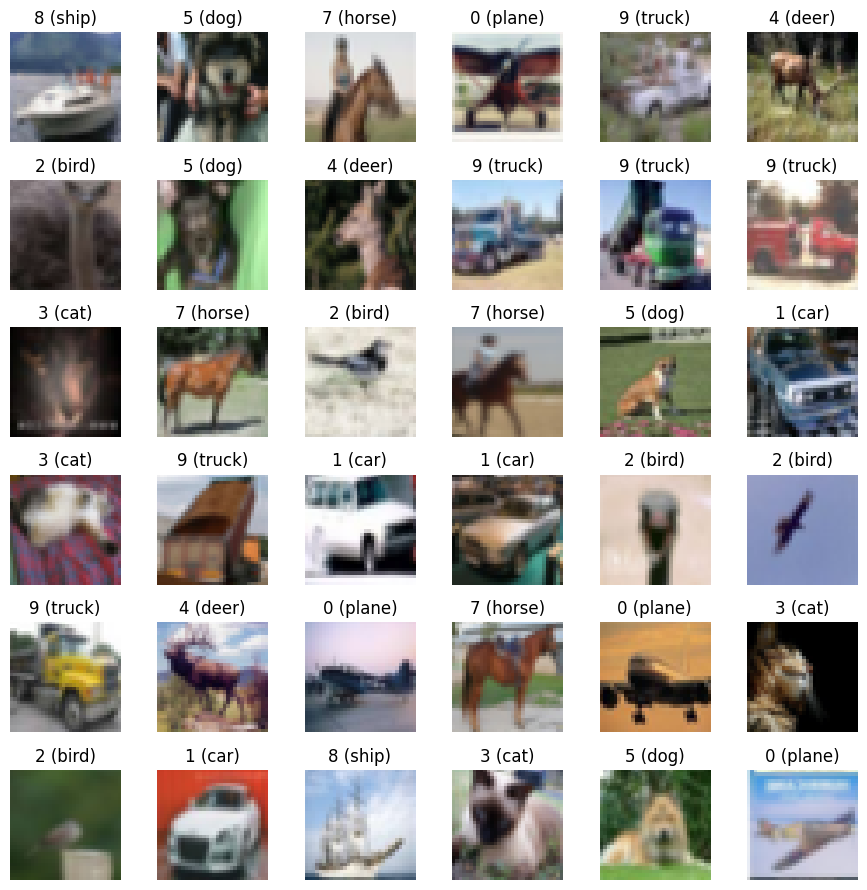

In [8]:
it_entdl = iter(ent_dl)
lote_ent = next(it_entdl)

print(f'Imágenes = {lote_ent[0].shape}, Categorías = {lote_ent[1].shape}')
muestra_imagenes(unnorm(lote_ent[0])[:N_IMGS_MUESTRA].permute(0, 2, 3, 1).numpy(),
                 lote_ent[1][:N_IMGS_MUESTRA].numpy(), i2c)

Hacemos lo mismo para el lote de validación.

Imágenes = torch.Size([64, 3, 32, 32]), Categorías = torch.Size([64])


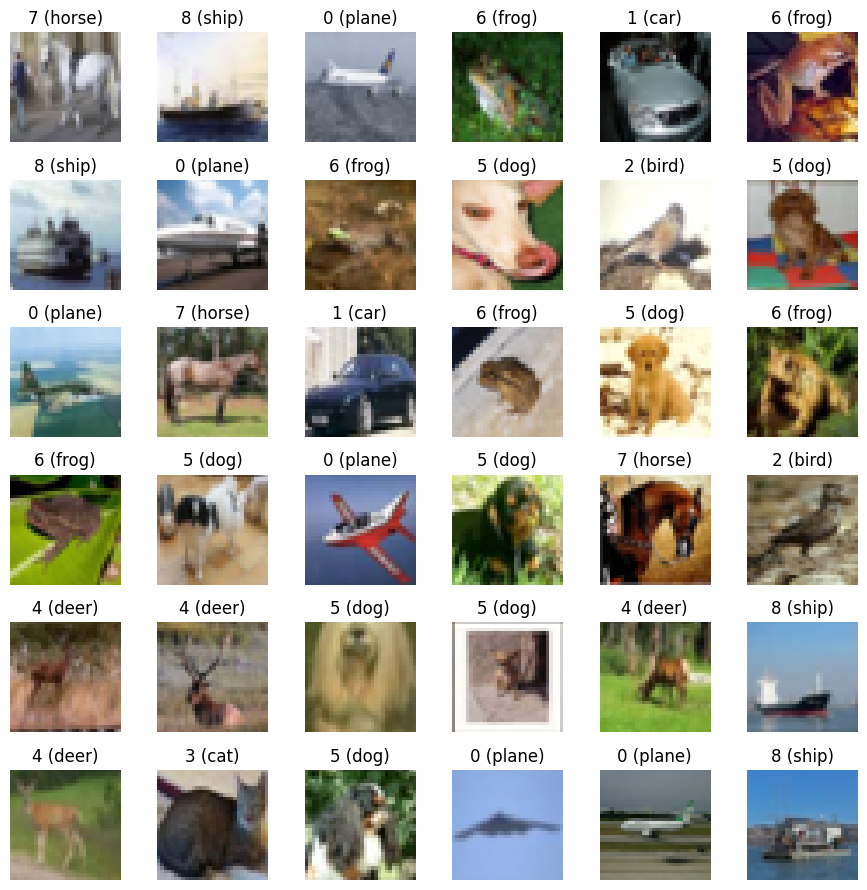

In [9]:
it_valdl = iter(val_dl)
lote_val = next(it_valdl)

print(f'Imágenes = {lote_val[0].shape}, Categorías = {lote_val[1].shape}')
muestra_imagenes(unnorm(lote_val[0])[:N_IMGS_MUESTRA].permute(0, 2, 3, 1).numpy(),
                 lote_val[1][:N_IMGS_MUESTRA].numpy(), i2c)

## Arquitectura
Se define la arquitectura Vision Transformer (ViT), propuesta en el artículo [An Image is Worth 16x16 Words: Transformers for Image Recognition at Scale](https://arxiv.org/abs/2010.11929). Esta arquitectura está basada en bloques Transformer.

### Producto punto escalado
La función de puntaje del producto punto escalado entre el $i$-ésimo vector de consulta $\mathbf{q}^{[i]}\in \mathbb{R}^{d_k}$ y el $j$-ésimo vector de llave $\mathbf{k}^{[j]} \in \mathbb{R}^{d_k}$ está definida como:
$$
\operatorname{puntaje}(\mathbf{q}^{[i]}, \mathbf{k}^{[j]}) = \frac{\mathbf{q}^{[i] \top} \mathbf{k}^{[j]}}{\sqrt{d_k}},
$$

donde $i,j \in \{1, \ldots, T\}$. Su valor de atención $\alpha_{i,j}$ se obtiene aplicando la función softmax sobre los puntajes de la consulta $i$ con todas las llaves:
$$
\alpha_{i,j} = \frac{\exp\left(\operatorname{puntaje}(\mathbf{q}^{[i]}, \mathbf{k}^{[j]})\right)}{\sum_{t=1}^{T} \exp\left(\operatorname{puntaje}(\mathbf{q}^{[i]}, \mathbf{k}^{[t]})\right)}
$$

In [10]:
class ProductoPuntoEscalado(nn.Module):
  def __init__(self):
    super(ProductoPuntoEscalado, self).__init__()

  def forward(self, Q, K, V):
    # Obtenemos dimensiones
    m, n_cabezas, l, d_k = K.shape
    d_v = V.shape[-1]

    # Cambiamos la forma de Q, K y V para calcular el producto punto
    # [m, n_cabezas, l, d_k] -> [m * n_cabezas, l, d_k]
    Q = Q.reshape(m * n_cabezas, l, d_k)
    K = K.reshape(m * n_cabezas, l, d_k)
    V = V.reshape(m * n_cabezas, l, d_v)

    # Q y K tienen forma [m * n_cabezas, l, d_k], por lo que se transponen
    # las dos últimas dimensiones de K a [m * n_cabezas, d_k, l] para pasarlas a la función bmm (multiplicación
    # de lotes de matrices). Esta función multiplica cada una de las m * n_cabezas
    # matrices de lxd_k en Q con la correspondiente matriz de d_kxl en la
    # transpuesta de K, resultando en m * n_cabezas matrices de lxl.
    # QK.T: [m * n_cabezas, l, l]
    QK = th.bmm(Q, K.transpose(1, 2))

    # se escalan los valores QK dividiendo entre sqrt(d_k)
    QK_esc = QK / sqrt(d_k)

    # se aplica la función softmax sobre la última dimensión de los mapas
    # de atención.
    # [m * n_cabezas, l, l] -> [m * n_cabezas, l, l]
    alfas = nn.functional.softmax(QK_esc, dim=-1)

    # Se calculan los vectores de salida como la suma de todos los vectores
    # V en cada cabeza multiplicados por sus mapas de atención. Esto se
    # realiza usando la función bmm, la cual multiplica cada una de las m * n_cabezas
    # matrices de lxl en alfas con la correspondiente matriz de lxd_v en V,
    # resultando en m * n_cabezas matrices de lxd_v.
    # alfas: [m * n_cabezas, l, l], V: [m * n_cabezas, l, d_v]
    # Y: [m * n_cabezas, l, d_v]
    Y = th.bmm(alfas, V)

    # Desagrupamos las dimensiones de ejemplos y de cabezas en las salidas
    # [m * n_cabezas, l, d_v] -> [m, n_cabezas, l, d_v]
    Y = Y.reshape(m, n_cabezas, l, d_v)

    # Desagrupamos las dimensiones de ejemplos y de cabezas en los mapas de atención
    # [m * n_cabezas, l, l] -> [m, n_cabezas, l, l]
    alfas = alfas.reshape(m, n_cabezas, l, l)

    return Y, alfas

ppe = ProductoPuntoEscalado()
ppe(th.rand([1, 4, 10, 64]), # Q
    th.rand([1, 4, 10, 64]), # K
    th.rand([1, 4, 10, 64]))[0].shape # V

torch.Size([1, 4, 10, 64])

### Atención multicabeza
En la autoatención de la arquitectura Transformer, cada vector $\mathbf{x}^{[i]} \in \mathbb{R}^{d_{modelo} \times 1}$ en la secuencia se transforma en tres vectores usando las matrices entrenables $\mathbf{W}_q \in \mathbb{R}^{d_k \times d_{modelo}}$, $\mathbf{W}_k \in \mathbb{R}^{d_k \times d_{modelo}}$ y $\mathbf{W}_v \in \mathbb{R}^{d_v \times d_{modelo}}$: uno conocido como consulta $\mathbf{q}^{[i]} \in \mathbb{R}^{d_k \times 1}$, otro como llave $\mathbf{k}^{[i]} \in \mathbb{R}^{d_k \times 1}$ y un tercero como valor $\mathbf{v}^{[i]} \in \mathbb{R}^{d_v \times 1}$:

\begin{align*}
\mathbf{q}^{[i]} & = \mathbf{W}_q \mathbf{x}^{[i]}\\
\mathbf{k}^{[i]} & =  \mathbf{W}_k \mathbf{x}^{[i]}\\
\mathbf{v}^{[i]} & = \mathbf{W}_v \mathbf{x}^{[i]}
\end{align*}

El $i$-ésimo vector de salida $\mathbf{a}^{[i]} \in \mathbb{R}^{d_v \times 1}$ en la secuencia se obtiene calculando la suma de cada vector de valor $\mathbf{v}^{[j]}$ ponderado por su valor de atención $\alpha_{i,j}$:
$$
\mathbf{a}^{[i]} = \sum_{j=1}^T \alpha_{i,j}\cdot \mathbf{v}^{[j]}
$$

Para llevar a cabo la atención multicabeza, esta operación se lleva a cabo con $h$ conjuntos distintos de matrices entrenables, con $d_k = d_v = d_{modelo} / h$, y se concatenan los $h$ vectores de salida resultantes de la $i$-ésima posición en un solo vector $\mathbf{o}^{[i]} \in \mathbb{R}^{(h \cdot d_v) \times 1}$:
$$
\mathbf{o}^{[i]} = [\mathbf{a}^{[i]}_1;\cdots;\mathbf{a}^{[i]}_h]
$$

Este vector se multiplica por la matriz entrenable $\mathbf{W}_o \in \mathbb{R}^{d_{modelo} \times (h \cdot d_v)}$ para producir el vector de salida $\mathbf{y}^{[i]}  \in \mathbb{R}^{d_{modelo} \times 1}$ de la autoatención multicabeza:

$$
\mathbf{y}^{[i]} = \mathbf{W}_o \cdot \mathbf{o}^{[i]}
$$

<img src="https://machinelearningmastery.com/wp-content/uploads/2021/09/tour_4.png">

Imagen tomada de [https://arxiv.org/abs/1706.03762](https://arxiv.org/abs/1706.03762).

In [11]:
class AtencionMulticabeza(nn.Module):
  def __init__(self,
               d_modelo: int,
               n_cabezas: int) -> None:
    super(AtencionMulticabeza, self).__init__()

    assert d_modelo % n_cabezas == 0, 'd_modelo debe ser divisible entre n_cabezas'

    self.n_cabezas = n_cabezas
    self.d_modelo = d_modelo

    self.d_k = self.d_modelo // self.n_cabezas

    self.ppe = ProductoPuntoEscalado()

    self.proy_Q = nn.Linear(self.d_modelo, self.d_modelo, bias = False)
    self.proy_K = nn.Linear(self.d_modelo, self.d_modelo, bias = False)
    self.proy_V = nn.Linear(self.d_modelo, self.d_modelo, bias = False)

    self.proy_sal = nn.Linear(self.d_modelo, self.d_modelo)

  def forward(self,
              x: th.Tensor) -> th.Tensor:
    m, l, d_modelo = x.shape

    # Cambiamos la forma del tensor de entrada x
    # para proyectarlo con Wq, Wk y Wv
    # [m, l, d_modelo] -> [m * l, d_modelo]
    x = x.reshape(m * l, d_modelo)

    # Proyectamos vectores en x a Q, K, V
    # [m * l, d_modelo] -> [m * l, d_modelo]
    Q = self.proy_Q(x)
    K = self.proy_K(x)
    V = self.proy_V(x)

    # Dividimos vectores de d_modelo en n_cabezas
    # de d_k.
    # [m * l, d_modelo] -> [m, l, n_cabezas, d_k]
    # d_k = d_v = self.d_modelo // self.n_cabezas
    Q = Q.reshape(m, l, self.n_cabezas, self.d_k)
    K = K.reshape(m, l, self.n_cabezas, self.d_k)
    V = V.reshape(m, l, self.n_cabezas, self.d_k)

    # Transponemos el eje de las cabezas a la segunda posición del tensor
    # y el de la secuencia a la tercera para pasarlo por el producto punto
    # escalado. Creamos copia (con .contiguous()) para que esté almacenado
    # en memoria de forma contigua (.transpose() hace que ya no sea así).
    # [m, l, n_cabezas, d_k] -> [m, n_cabezas, l, d_k]
    Q = Q.transpose(1, 2).contiguous()
    K = K.transpose(1, 2).contiguous()
    V = V.transpose(1, 2).contiguous()

    # Calculamos el producto punto escalado con Q, K y V
    # Q, K, V, Y: [m, n_cabezas, l, d_k]
    Y, _ = self.ppe(Q, K, V)

    # Regresamos el eje de cabezas a la tercera posición y el de la
    # secuencia a la segunda (como estaba originalmente).
    # [m, n_cabezas, l, d_k] -> [m, l, n_cabezas, d_k]
    Y = Y.transpose(1, 2).contiguous()

    # Concatenamos los vectores de todas las cabezas en un solo vector
    # para pasarlos por la capa de proyección de salida Wo, agrupando
    # dimensiones de ejemplos y secuencia.
    # [m, l, n_cabezas, d_k] -> [m * l, d_modelo]
    # d_modelo = n_cabezas * d_k
    Y = Y.reshape(m * l, self.d_modelo)

    # Proyectamos los vectores concatenados para obtener la salida
    # [m * l, d_modelo] -> [m * l, d_modelo]
    Y = self.proy_sal(Y)

    # Desagrupamos dimensiones de ejemplos y secuencia
    # [m * l, d_modelo] -> [m, l, d_modelo]
    Y = Y.reshape(m, l, self.d_modelo)

    return Y

amc = AtencionMulticabeza(256, 2)
amc(th.rand([1, 10, 256])).shape

torch.Size([1, 10, 256])

### Red hacia adelante por posición
Cada vector de la secuencia de salida de la autoatención multicabeza se procesa de forma independiente mediante una red hacia adelante por posición, compuesta por 2 capas densas cuyos parámetros son los mismos para todas las posiciones:

$$
\hat{\mathbf{y}}^{[i]} = \mathbf{W}^{\{2\}}\,\phi\left(\mathbf{W}^{\{1\}}\,\mathbf{y}^{[i]} + \mathbf{b}^{\{1\}}\right) + \mathbf{b}^{\{2\}},
$$

donde $\mathbf{y}^{[i]}$ es el $i$-ésimo vector en la secuencia y $\phi$ es una función de activación. En la arquitectura original, $\phi$ es la $\operatorname{ReLU}$, mientras que GPT, BERT y ViT emplean la $\operatorname{GELU}$.

In [12]:
class RedDensaPosicion(nn.Module):
  def __init__(self,
               d_modelo,
               d_rdp,
               p_dropout):
    super(RedDensaPosicion, self).__init__()

    self.d_modelo = d_modelo
    self.d_rdp = d_rdp

    self.densa1 = nn.Linear(self.d_modelo, self.d_rdp)
    self.densa2 = nn.Linear(self.d_rdp, self.d_modelo)

    self.dropout1 = nn.Dropout(p_dropout)
    self.dropout2 = nn.Dropout(p_dropout)

  def forward(self, x):
    # Pasamos el tensor de entrada por primera capa densa
    # función de activación GELU y dropout
    # [m, l, d_modelo] -> [m, l, d_rdp]
    x = self.densa1(x)
    x = nn.functional.gelu(x)
    x = self.dropout1(x)

    # Pasamos el tensor resultante de capas anteriores por segunda capa densa,
    # y dropout
    # [m, l, d_rdp] -> [m, l, d_modelo]
    x = self.densa2(x)
    x = self.dropout2(x)

    return x

rdp = RedDensaPosicion(256, 512, 0.2)
rdp(th.rand([1, 10, 256])).shape

torch.Size([1, 10, 256])

### Bloque Transformer
El bloque Transformer está compuesto por dos subbloques: la atención multicabeza y la red hacia adelante por posición. Cada subbloque normaliza por capas su entrada, aplica _dropout_ a su salida y tiene una conexión residual:
$$
\begin{aligned}
\mathbf{h} & = \mathbf{x} + \operatorname{Dropout}\left(\operatorname{AMC}(\operatorname{LN}(\mathbf{x}))\right),\\
\mathbf{z} & = \mathbf{h} + \operatorname{Dropout}\left(\operatorname{RDP}(\operatorname{LN}(\mathbf{h}))\right)
\end{aligned}
$$

donde $\operatorname{AMC}$ es la atención multicabeza, $\operatorname{RDP}$ la red hacia adelante por posición y $\operatorname{LN}$ la normalización por capas. Nota que a diferencia del bloque Transformer original, en el que $\mathbf{h} = \operatorname{LN}\left(\mathbf{x} + \operatorname{Dropout}(\operatorname{AMC}(\mathbf{x}))\right)$, la normalización por capas se realiza a la entrada de cada subbloque en lugar de a la salida de las conexiones residuales.

<img src="https://theaisummer.com/static/aa65d942973255da238052d8cdfa4fcd/7d4ec/the-transformer-block-vit.png">

Imagen tomada de https://arxiv.org/abs/2010.11929.

In [13]:
class BloqueTransformer(nn.Module):
  def __init__(self,
               d_modelo,
               n_cabezas,
               d_rdp,
               p_dropout=0.0):
    super(BloqueTransformer, self).__init__()

    self.amc = AtencionMulticabeza(d_modelo=d_modelo,
                                   n_cabezas=n_cabezas)
    self.norm1 = nn.LayerNorm(d_modelo)
    self.norm2 = nn.LayerNorm(d_modelo)

    self.dropout1 = nn.Dropout(p_dropout)

    self.mlp = RedDensaPosicion(d_modelo, d_rdp, p_dropout)

  def forward(self, x):
    x = x + self.dropout1(self.amc(self.norm1(x)))
    x = x + self.mlp(self.norm2(x))
    return x

bt = BloqueTransformer(256, 4, 512, 0.2)
bt(th.rand([1, 10, 256])).shape

torch.Size([1, 10, 256])

### ViT
Definimos la clase para la arquitectura ViT, la cual está compuesta por varios bloques Transformer. Como entrada recibe una imagen $\mathbf{I}^{(i)}$ de tamaño $H \times W \times C$ y la divide en $B$ parches $\mathbf{x}_k^{(i)}, k = 1, \ldots, B$ de tamaño $P \times P \times C$, donde $B = \frac{H \cdot W}{P^2}$ (con $H$ y $W$ múltiplos de $P$). Podemos realizar esta operación con la biblioteca [einops](https://einops.rocks), la cual está inspirada en la notación de suma de Einstein.

Tomemos una imagen de ejemplo.

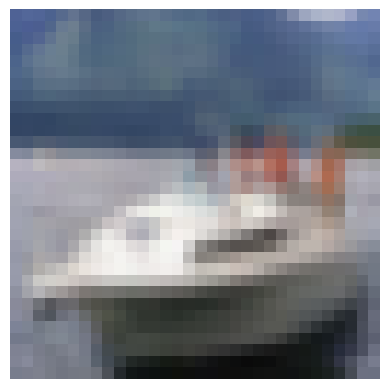

In [14]:
plt.imshow(unnorm(lote_ent[0][0]).permute(1, 2, 0).clamp(0, 1))
plt.axis('off')
plt.show()

Reorganizamos el tensor dividiendo cada imagen en parches de $P \times P \times C$ y aplanando cada parche en un vector de $P^2 C$ elementos. Con parches de $8 \times 8$ en imágenes RGB, cada vector tiene $8 \cdot 8 \cdot 3 = 192$ elementos.

In [15]:
# [m, c, h, w] -> [m, n_h * n_w, p_h * p_w * c]
parches = rearrange(lote_ent[0],
                    'm c (n_h p_h) (n_w p_w) -> m (n_h n_w) (p_h p_w c)',
                    p_h = T_PARCHES, p_w = T_PARCHES)
print(f'Parches = {parches.shape}')

Parches = torch.Size([64, 64, 48])


Visualizamos los parches en el orden en que forman la secuencia de entrada, de izquierda a derecha y de arriba hacia abajo.

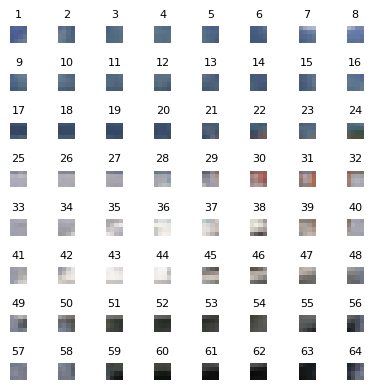

In [16]:
n_lado = T_IMG[0] // T_PARCHES

fig, axs = plt.subplots(nrows=n_lado, ncols=n_lado, figsize=(4, 4))
for i in range(n_lado * n_lado):
  # [p_h * p_w * c] -> [c, p_h, p_w]
  parche = rearrange(parches[0, i], '(p_h p_w c) -> c p_h p_w',
                     p_h = T_PARCHES, p_w = T_PARCHES)
  # [c, p_h, p_w] -> [p_h, p_w, c]
  parche = unnorm(parche).permute(1, 2, 0)

  ax = axs[i // n_lado, i % n_lado]
  ax.imshow(parche.clamp(0, 1))
  ax.set_title(f'{i + 1}', fontsize=8)
  ax.axis('off')
plt.tight_layout()
plt.show()

Cada parche se aplana y se proyecta con una capa densa, obteniendo como resultado un vector de $d$ dimensiones. Los vectores asociados a los parches de la imagen se procesan como una secuencia, al inicio de la cual se agrega un vector entrenable llamado CLS. A cada uno de los $B + 1$ vectores de la secuencia se le suma un vector de codificación posicional entrenable, distinto para cada posición, y posteriormente la secuencia se pasa por varios bloques Transformer. El vector correspondiente a CLS en la secuencia de salida del último bloque Transformer se pasa por una normalización por capas y una capa densa que sirve como clasificador. La función softmax no se incluye en el modelo porque `CrossEntropyLoss` la aplica internamente.

<img src="https://upload.wikimedia.org/wikipedia/commons/9/93/Vision_Transformer.png">

Imagen tomada de [https://en.wikipedia.org/wiki/Vision_transformer](https://en.wikipedia.org/wiki/Vision_transformer).

In [17]:
class ViT(nn.Module):
  def __init__(self,
               t_img: int,
               t_parches: int,
               n_clases: int,
               d_embed: int,
               n_capas: int,
               n_cabezas: int,
               rdp_dim: int,
               p_dropout: float,
               n_canales: int = 3):
    super(ViT, self).__init__()

    assert t_img % t_parches == 0, 't_img debe ser múltiplo de t_parches'

    self.t_parches = t_parches

    # número de parches = (alto_imagen * ancho_imagen) / (tamaño_parche^2)
    self.n_parches = (t_img // t_parches) ** 2

    # proyección de parches aplanados de P x P x C a d_embed
    self.proyeccion = nn.Linear(t_parches * t_parches * n_canales, d_embed)

    # codificación posicional entrenable, un vector por posición
    self.emb_pos = nn.Parameter(th.zeros(1, self.n_parches + 1, d_embed))

    # vector CLS entrenable
    self.token_cls = nn.Parameter(th.zeros(1, 1, d_embed))

    # inicializamos con una normal truncada de desviación 0.02 como en ViT
    nn.init.trunc_normal_(self.emb_pos, std = 0.02)
    nn.init.trunc_normal_(self.token_cls, std = 0.02)

    # bloques transformer
    bloques = [BloqueTransformer(d_embed,
                                 n_cabezas,
                                 rdp_dim,
                                 p_dropout) for _ in range(n_capas)]
    self.transformer = nn.Sequential(*bloques)

    # clasificador
    self.clasificador = nn.Sequential(nn.LayerNorm(d_embed),
                                      nn.Linear(d_embed, n_clases))

  def forward(self, x):
    # x: [m, c, h, w]
    m = x.shape[0]

    # dividimos la imagen de entrada en una secuencia de b = n_h * n_w vectores
    # los cuales están compuestos por los píxeles asociados a los parches
    # de t_parches * t_parches * c.
    # [m, c, h, w] -> [m, b, t_parches * t_parches * c]
    parches = rearrange(x,
                        'm c (n_h p_h) (n_w p_w) -> m (n_h n_w) (p_h p_w c)',
                        p_h = self.t_parches, p_w = self.t_parches)

    # proyectamos los vectores de los parches para obtener sus representaciones
    # [m, b, t_parches * t_parches * c] -> [m, b, d_embed]
    x = self.proyeccion(parches)

    # vector CLS inicia con los mismos valores para todos los ejemplos
    # [1, 1, d_embed] -> [m, 1, d_embed]
    token_cls = self.token_cls.expand(m, -1, -1)

    # se concatenan los vectores iniciales de CLS a secuencias de vectores
    # de parches
    # token_cls: [m, 1, d_embed], x: [m, b, d_embed] -> [m, b + 1, d_embed]
    x = th.cat((token_cls, x), dim = 1)

    # sumamos codificación posicional a vectores de representación de parches
    # [m, b + 1, d_embed] -> [m, b + 1, d_embed]
    x = x + self.emb_pos

    # pasamos secuencia por bloques Transformer
    # [m, b + 1, d_embed] -> [m, b + 1, d_embed]
    x = self.transformer(x)

    # extraemos vector asociado a CLS de secuencia de salida de bloques Transformer
    # [m, b + 1, d_embed] -> [m, d_embed]
    x = x[:, 0, :]

    # pasamos vector por clasificador
    # [m, d_embed] -> [m, n_clases]
    x = self.clasificador(x)

    return x

modelo = ViT(T_IMG[0],
             t_parches = T_PARCHES,
             n_clases = len(c2i),
             d_embed = D_EMBED,
             n_capas = N_CAPAS,
             n_cabezas = N_CABEZAS,
             rdp_dim = RDP_DIM,
             p_dropout = P_DROPOUT)
modelo(th.rand(1, 3, T_IMG[0], T_IMG[1])).shape

torch.Size([1, 10])

Calculamos el número de parámetros del modelo.

In [18]:
n_params = sum(p.numel() for p in modelo.parameters())
print(f'{n_params} parámetros')

807818 parámetros


## Funciones para el entrenamiento
Para facilitar el entrenamiento, definimos diversas funciones.

### Guardar _checkpoint_
Definimos una función para guardar el estado del entrenamiento y del modelo usando la función `save`.

In [19]:
def guarda_ckpt(ckptpath: str,
                modelo: nn.Module,
                epoca: int,
                opt: th.optim.Optimizer) -> None:
  estado_modelo = {'epoch': epoca,
                   'model_state_dict': modelo.state_dict(),
                   'optimizer_state_dict': opt.state_dict()}
  th.save(estado_modelo, ckptpath)

### Registrar información para Tensorboard
Para guardar información que pueda visualizarse con Tensorboard, instanciamos la clase `SummaryWriter` del submódulo `tensorboard` del módulo `utils` y escribimos información mediante los distintos métodos disponibles (por ej. `add_scalar`, `add_image`, `add_histogram`, etc.).

In [20]:
def registra_info_tboard(writer: SummaryWriter,
                         epoca: int,
                         hist: dict[str, dict[str, np.ndarray]]) -> None:
  for (p, vp) in hist.items():
    for (m, vm) in vp.items():
      writer.add_scalar(f'{m}/{p}', vm[epoca], epoca)

### Paso de entrenamiento
Definimos una función que realiza un paso de entrenamiento, a la cual llamaremos `paso_ent`. Esta función recibe como argumentos:
- El modelo como una instancia de `Module` (`modelo`).
- La función de pérdida (`fp`).
- La métrica a evaluar (`metrica`).
- Una instancia de `Optimizer` del módulo `optim` de PyTorch para actualizar los pesos y sesgos (`opt`).
- Una instancia de `LRScheduler` del módulo `optim` de PyTorch para actualizar el programador de la tasa de aprendizaje (`sched`).
- Una instancia de `Tensor` con el lote de imágenes de entrada (`X`).
- Una instancia de `Tensor` con el lote de etiquetas (`y`).
- El dispositivo en el que se ejecutará el modelo (`disp`).

La función obtiene las predicciones del modelo para las entradas, calcula la pérdida, obtiene los gradientes, actualiza todos los parámetros del modelo mediante el optimizador pasado como argumento y actualiza la tasa de aprendizaje. La precisión mixta con `bfloat16` solo se habilita en GPU con soporte nativo (capacidad de cómputo 8.0 o mayor, por ejemplo A100 o L4). En una T4 el entrenamiento se realiza en `float32`.

In [21]:
def paso_ent(modelo: nn.Module,
             fp: nn.Module | Callable,
             metrica: torchmetrics.Metric,
             opt: th.optim.Optimizer,
             sched: th.optim.lr_scheduler.LRScheduler,
             X: th.Tensor,
             y: th.Tensor,
             disp: str | th.device) -> th.Tensor:
  # Ponemos los gradientes asociados a los parámetros
  # a actualizar en cero
  opt.zero_grad()

  tipo_disp = th.device(disp).type

  # Se habilita precisión mixta solo si el dispositivo es cuda y
  # soporta bfloat16 de forma nativa (capacidad de cómputo >= 8.0)
  usa_amp = (tipo_disp == 'cuda' and th.cuda.get_device_capability(disp)[0] >= 8)

  with th.autocast(device_type = tipo_disp,
                   dtype = th.bfloat16, enabled = usa_amp):
    # Propagamos las entradas para obtener las predicciones
    y_hat = modelo(X)

    # Calculamos la pérdida
    perdida = fp(y_hat, y)

  metrica.update(y_hat.detach(), y)

  # Obtenemos los gradientes
  perdida.backward()

  # Actualizamos todos los parámetros del modelo
  opt.step()

  # Actualizamos tasa de aprendizaje
  sched.step()

  # Desconectamos la pérdida del grafo de cómputo
  perdida_paso = perdida.detach()

  return perdida_paso

### Época de entrenamiento
Definimos una función para realizar una época de entrenamiento, que llamaremos `entrena_epoca`. Esta función recibe como argumentos:
- El modelo como una instancia de `Module` (`modelo`).
- La función de pérdida (`fp`).
- La métrica a evaluar (`metrica`).
- Una instancia de `Optimizer` del módulo `optim` de PyTorch para actualizar los pesos y sesgos (`opt`).
- Una instancia de `LRScheduler` del módulo `optim` de PyTorch para actualizar el programador de la tasa de aprendizaje (`sched`).
- El cargador de datos del subconjunto de entrenamiento (`dl`).
- El dispositivo en el que se ejecutará el modelo (`disp`).

In [22]:
def entrena_epoca(modelo: nn.Module,
                  fp: nn.Module | Callable,
                  metrica: torchmetrics.Metric,
                  opt: th.optim.Optimizer,
                  sched: th.optim.lr_scheduler.LRScheduler,
                  dl: th.utils.data.DataLoader,
                  disp: str | th.device = 'cpu') -> tuple[float, float]:
  n_total = 0
  suma_perdida = 0.0

  modelo.train()
  metrica.reset()
  for X, y in dl:
    X = X.to(disp)
    y = y.to(disp)

    perdida_paso = paso_ent(modelo,
                            fp,
                            metrica,
                            opt,
                            sched,
                            X,
                            y,
                            disp)

    n_lote = y.shape[0]
    n_total += n_lote

    # Asumiendo que la pérdida tiene reduction='mean'
    suma_perdida += perdida_paso * n_lote

  perdida_epoca = (suma_perdida / n_total).item()

  return perdida_epoca, metrica.compute().item()

### Evaluación
Definimos la función `evalua` para evaluar el modelo en un subconjunto de datos. Esta función recibe como argumentos:

- El modelo como una instancia de `Module` (`modelo`).
- La función de pérdida (`fp`).
- La métrica a evaluar (`metrica`).
- El cargador de datos del subconjunto (`dl`).
- El dispositivo en el que se ejecutará el modelo (`disp`).

In [23]:
@th.inference_mode()
def evalua(modelo: nn.Module,
           fp: nn.Module | Callable,
           metrica: torchmetrics.Metric,
           dl: th.utils.data.DataLoader,
           disp: str | th.device = 'cpu') -> tuple[float, float]:
  n_total = 0
  suma_perdida = 0.0

  tipo_disp = th.device(disp).type

  # Se habilita precisión mixta solo si el dispositivo es cuda y
  # soporta bfloat16 de forma nativa (capacidad de cómputo >= 8.0)
  usa_amp = (tipo_disp == 'cuda' and th.cuda.get_device_capability(disp)[0] >= 8)

  modelo.eval()
  metrica.reset()
  for X, y in dl:
    X = X.to(disp)
    y = y.to(disp)

    n_lote = y.shape[0]
    n_total += n_lote

    with th.autocast(device_type = tipo_disp,
                     dtype = th.bfloat16, enabled = usa_amp):
      # Propagamos las entradas para obtener las predicciones
      y_hat = modelo(X)

      # Asumiendo que la pérdida tiene reduction='mean'
      suma_perdida += fp(y_hat, y) * n_lote

    metrica.update(y_hat, y)

  perdida_total = (suma_perdida / n_total).item()

  return perdida_total, metrica.compute().item()

### Ciclo principal
También definimos el ciclo de entrenamiento principal, que llamaremos `entrena`. Esta función recibe como argumentos:
- El modelo como una instancia de `Module` (`modelo`).
- La función de pérdida (`fp`).
- La métrica a evaluar (`metrica`).
- Una instancia de `Optimizer` del módulo `optim` de PyTorch para actualizar los pesos y sesgos (`opt`).
- Una instancia de `LRScheduler` del módulo `optim` de PyTorch para actualizar el programador de la tasa de aprendizaje (`sched`).
- El cargador de datos del subconjunto de entrenamiento (`entdl`).
- El cargador de datos del subconjunto de validación (`valdl`).
- El dispositivo en el que se ejecutará el modelo (`disp`).
- La ruta al archivo donde se guardará el estado del entrenamiento y el modelo (`ckptpath`).
- El número de épocas de entrenamiento (`n_epocas`).
- La ruta al directorio donde se guardará la información para Tensorboard (`tbdir`).

En cada época se realiza un paso de entrenamiento por cada lote del subconjunto de entrenamiento y, al final de la época, se calcula la pérdida en el subconjunto de validación. Se conserva una copia del modelo con la menor pérdida de validación (`mejor_modelo`).

In [24]:
def entrena(modelo: nn.Module,
            fp: nn.Module | Callable,
            metrica: torchmetrics.Metric,
            opt: th.optim.Optimizer,
            sched: th.optim.lr_scheduler.LRScheduler,
            entdl: th.utils.data.DataLoader,
            valdl: th.utils.data.DataLoader,
            disp: str | th.device,
            ckptpath: str | None = None,
            n_epocas: int = 10,
            nombre_metrica: str | None = None,
            tbdir: str = 'runs/') -> tuple[nn.Module, nn.Module, dict[str, dict[str, np.ndarray]]]:

  if nombre_metrica is None:
    nombre_metrica = metrica._get_name().lower()

  hist = {
    'ent': {
      'perdida': np.zeros(n_epocas),
      nombre_metrica: np.zeros(n_epocas)
    },
    'val': {
      'perdida': np.zeros(n_epocas),
      nombre_metrica: np.zeros(n_epocas)
    }
  }

  tbwriter = SummaryWriter(tbdir)
  perdida_min = th.inf

  modelo.to(disp)
  metrica.to(disp)
  mejor_modelo = copy.deepcopy(modelo)

  for e in range(n_epocas):
    # Bucle de entrenamiento
    hist['ent']['perdida'][e], hist['ent'][nombre_metrica][e] = entrena_epoca(modelo,
                                                                              fp,
                                                                              metrica,
                                                                              opt,
                                                                              sched,
                                                                              entdl,
                                                                              disp)

    # Bucle de validación
    hist['val']['perdida'][e], hist['val'][nombre_metrica][e] = evalua(modelo,
                                                                       fp,
                                                                       metrica,
                                                                       valdl,
                                                                       disp)

    # guardamos checkpoint y copiamos pesos y sesgos del modelo
    # actual si disminuye la pérdida en validación
    if hist['val']['perdida'][e] < perdida_min:
      mejor_modelo.load_state_dict(modelo.state_dict())
      perdida_min = hist['val']['perdida'][e]

      if ckptpath is not None:
        guarda_ckpt(ckptpath, modelo, e, opt)

    registra_info_tboard(tbwriter, e, hist)

    print(f'Época {e}: '
          f'Pérdida(E) = {hist["ent"]["perdida"][e]:.3f}, '
          f'{nombre_metrica}(E) = {hist["ent"][nombre_metrica][e]:.3f}, '
          f'Pérdida(V) = {hist["val"]["perdida"][e]:.3f}, '
          f'{nombre_metrica}(V) = {hist["val"][nombre_metrica][e]:.3f}')

  tbwriter.close()

  return modelo, mejor_modelo, hist

## Entrenamiento
Instanciamos el criterio para la pérdida, el optimizador, el programador de la tasa de aprendizaje y llamamos a la función `entrena`.

In [25]:
# pasamos modelo a GPU, si está disponible
modelo = modelo.to(DISP)

perdida = nn.CrossEntropyLoss(weight = None,
                              reduction = 'mean')

metrica = torchmetrics.Accuracy(task = 'multiclass',
                                num_classes = len(c2i))

opt = th.optim.AdamW(modelo.parameters(),
                     lr = LR,
                     weight_decay = WD)

pasos_totales = len(ent_dl) * N_EPOCAS
pasos_calentamiento = int(pasos_totales * 0.02)
sched = get_cosine_schedule_with_warmup(optimizer = opt,
                                        num_warmup_steps = pasos_calentamiento,
                                        num_training_steps = pasos_totales)

modelo, mejor_modelo, hist = entrena(modelo,
                                     perdida,
                                     metrica,
                                     opt,
                                     sched,
                                     ent_dl,
                                     val_dl,
                                     DISP,
                                     ckptpath = None,
                                     n_epocas = N_EPOCAS,
                                     nombre_metrica = 'exactitud',
                                     tbdir = LOGDIR)

Época 0: Pérdida(E) = 1.822, exactitud(E) = 0.321, Pérdida(V) = 1.601, exactitud(V) = 0.420
Época 1: Pérdida(E) = 1.439, exactitud(E) = 0.474, Pérdida(V) = 1.333, exactitud(V) = 0.514
Época 2: Pérdida(E) = 1.292, exactitud(E) = 0.533, Pérdida(V) = 1.301, exactitud(V) = 0.536
Época 3: Pérdida(E) = 1.203, exactitud(E) = 0.567, Pérdida(V) = 1.134, exactitud(V) = 0.587
Época 4: Pérdida(E) = 1.147, exactitud(E) = 0.587, Pérdida(V) = 1.144, exactitud(V) = 0.596
Época 5: Pérdida(E) = 1.096, exactitud(E) = 0.605, Pérdida(V) = 1.048, exactitud(V) = 0.627
Época 6: Pérdida(E) = 1.052, exactitud(E) = 0.623, Pérdida(V) = 1.036, exactitud(V) = 0.634
Época 7: Pérdida(E) = 1.016, exactitud(E) = 0.637, Pérdida(V) = 1.001, exactitud(V) = 0.645
Época 8: Pérdida(E) = 0.979, exactitud(E) = 0.650, Pérdida(V) = 0.989, exactitud(V) = 0.650
Época 9: Pérdida(E) = 0.947, exactitud(E) = 0.663, Pérdida(V) = 0.964, exactitud(V) = 0.664
Época 10: Pérdida(E) = 0.923, exactitud(E) = 0.674, Pérdida(V) = 0.966, exactitu

Graficamos la pérdida y la exactitud.

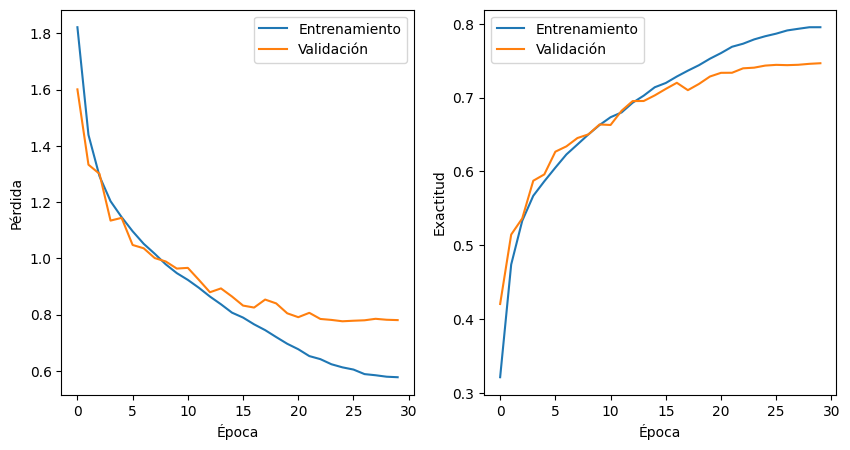

In [26]:
fig, axs = plt.subplots(nrows=1, ncols=2, figsize=(10, 5))

axs[0].plot(hist['ent']['perdida'], label='Entrenamiento')
axs[0].plot(hist['val']['perdida'], label='Validación')
axs[0].set_xlabel('Época')
axs[0].set_ylabel('Pérdida')
axs[0].legend()

axs[1].plot(hist['ent']['exactitud'], label='Entrenamiento')
axs[1].plot(hist['val']['exactitud'], label='Validación')
axs[1].set_xlabel('Época')
axs[1].set_ylabel('Exactitud')
axs[1].legend()
plt.show()

## Evaluación
Evaluamos el desempeño del modelo entrenado en el conjunto de validación.

In [27]:
mejor_modelo.eval()

pred_val, y_val = [], []
with th.no_grad():
  for Xlote, ylote in val_dl:
    pred_val.append(mejor_modelo(Xlote.to(DISP)).cpu().numpy())
    y_val.append(ylote.numpy())

pred_val = np.concatenate(pred_val).argmax(axis = 1)
y_val = np.concatenate(y_val)

print(f'F1 = {f1_score(y_val, pred_val, average = "macro"):.3f}\n'
      f'Exactitud = {(pred_val == y_val).mean():.3f}\n'
      f'Exhaustividad = {recall_score(y_val, pred_val, average = "macro"):.3f}\n'
      f'Precisión = {precision_score(y_val, pred_val, average = "macro"):.3f}\n'
      f'Matriz de confusión:\n {confusion_matrix(y_val, pred_val)}')

F1 = 0.740
Exactitud = 0.744
Exhaustividad = 0.745
Precisión = 0.742
Matriz de confusión:
 [[753  41  32  14  20   5  14  13  43  38]
 [ 31 841   5   1   3   1   4   5  26  62]
 [ 79  14 587  35 113  60  75  40  17  10]
 [ 20  11  39 502  73 204  98  46  13  17]
 [ 25   8  33  23 698  30  40  61   9   6]
 [ 10   9  26 113  63 663  42  71   7  11]
 [  6  12  25  22  44   7 866   3   9   2]
 [ 20   5  15  27  69  49  10 773   5  21]
 [ 55  30   4   2   7   3   2   3 890  21]
 [ 31 101   3   5   2   3   3  13  16 863]]
